In [32]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Download the Car Price assignment dataset from Kaggle
# (Note: Use the direct link provided in your portal, or the standard dataset path below)
path = kagglehub.dataset_download("vijayaadithyanvg/car-price-predictionused-cars")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'car-price-predictionused-cars' dataset.
Path to dataset files: /kaggle/input/car-price-predictionused-cars


In [33]:
import os

# 1. Automatically locate and read the downloaded CSV file
csv_file_path = os.path.join(path, "car data.csv")
df = pd.read_csv(csv_file_path)

# 2. Print initial shape and structural breakdown
print("Dataset Row & Column Count:", df.shape)
print("\n--- First 5 Rows ---")
print(df.head())

print("\n--- Dataset Info & Feature Types ---")
print(df.info())

Dataset Row & Column Count: (301, 9)

--- First 5 Rows ---
  Car_Name  Year  Selling_Price  Present_Price  Driven_kms Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Selling_type Transmission  Owner  
0       Dealer       Manual      0  
1       Dealer       Manual      0  
2       Dealer       Manual      0  
3       Dealer       Manual      0  
4       Dealer       Manual      0  

--- Dataset Info & Feature Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year   

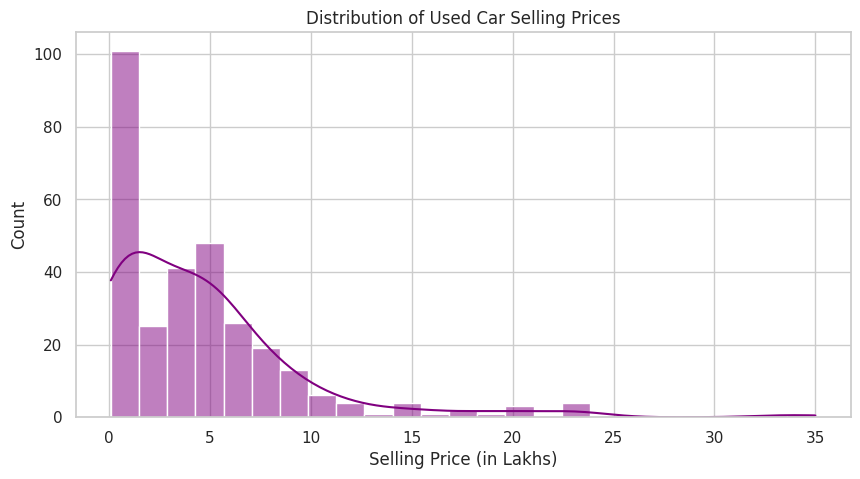

/tmp/ipykernel_6289/84829449.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fuel_Type', y='Selling_Price', data=df, palette='Set2')


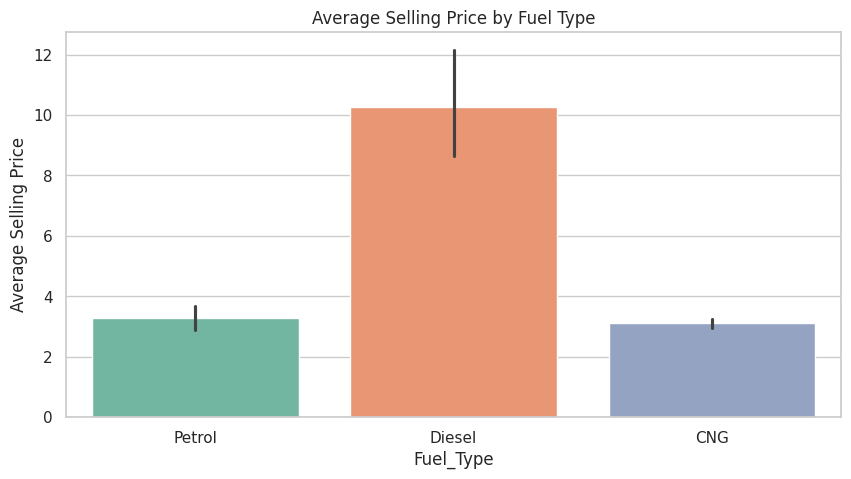

In [34]:
# Set visual theme configuration
sns.set_theme(style="whitegrid")

# 1. Distribution of Target Variable (Selling Price)
plt.figure(figsize=(10, 5))
sns.histplot(df['Selling_Price'], kde=True, color='purple', bins=25)
plt.title('Distribution of Used Car Selling Prices')
plt.xlabel('Selling Price (in Lakhs)')
plt.show()

# 2. Impact of Fuel Type on Price
plt.figure(figsize=(10, 5))
sns.barplot(x='Fuel_Type', y='Selling_Price', data=df, palette='Set2')
plt.title('Average Selling Price by Fuel Type')
plt.ylabel('Average Selling Price')
plt.show()

In [35]:
import os

# Load the Car Dekho dataset file from your kagglehub folder path
csv_file_path = os.path.join(path, "car data.csv")
df = pd.read_csv(csv_file_path)

# Clear hidden blank spaces from string names
df.columns = df.columns.str.strip()

print("Columns available:", df.columns.tolist())
print(df.head())

Columns available: ['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']
  Car_Name  Year  Selling_Price  Present_Price  Driven_kms Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Selling_type Transmission  Owner  
0       Dealer       Manual      0  
1       Dealer       Manual      0  
2       Dealer       Manual      0  
3       Dealer       Manual      0  
4       Dealer       Manual      0  


In [36]:
# Convert categorical string variables into numerical indicators (Dummy Encoding)
df_encoded = pd.get_dummies(df, columns=['Fuel_Type', 'Selling_type', 'Transmission'], drop_first=True)

# Select features (X) and our target label column (y)
# We drop 'Car_Name' because it contains too many unique text names, and 'Selling_Price' because it's our target.
X = df_encoded.drop(['Car_Name', 'Selling_Price'], axis=1)
y = df_encoded['Selling_Price']

print("Features ready for training:")
print(X.head())

Features ready for training:
   Year  Present_Price  Driven_kms  Owner  Fuel_Type_Diesel  Fuel_Type_Petrol  \
0  2014           5.59       27000      0             False              True   
1  2013           9.54       43000      0              True             False   
2  2017           9.85        6900      0             False              True   
3  2011           4.15        5200      0             False              True   
4  2014           6.87       42450      0              True             False   

   Selling_type_Individual  Transmission_Manual  
0                    False                 True  
1                    False                 True  
2                    False                 True  
3                    False                 True  
4                    False                 True  


In [37]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Split data matrix into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Instantiate and fit a Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Machine learning model training complete!")

Machine learning model training complete!


Model R² Score (Variance Explained): 0.8489 (or 84.89%)
Mean Absolute Error (MAE): 1.22 Lakhs


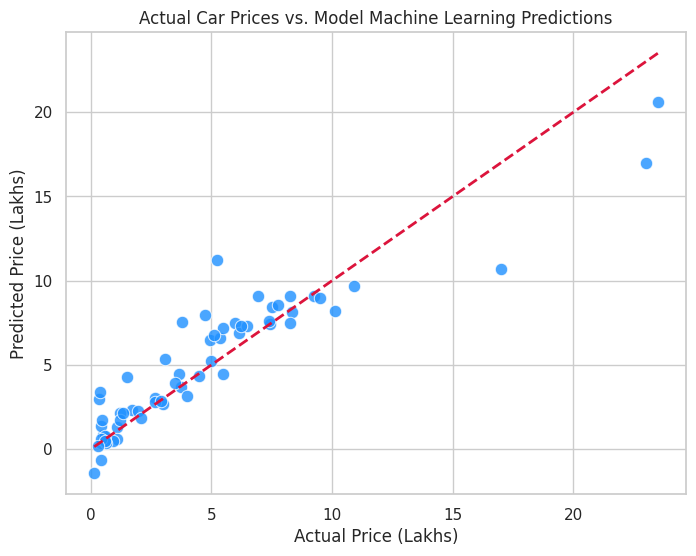

In [38]:
from sklearn.metrics import r2_score, mean_absolute_error

# Generate predictions on our testing partitions
y_pred = model.predict(X_test)

# Calculate standard accuracy parameters
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Model R² Score (Variance Explained): {r2:.4f} (or {r2*100:.2f}%)")
print(f"Mean Absolute Error (MAE): {mae:.2f} Lakhs")

# Scatter plot of Actual vs Predicted Car Prices
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, color='dodgerblue', alpha=0.8, s=80)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='crimson', linestyle='--', linewidth=2)
plt.title('Actual Car Prices vs. Model Machine Learning Predictions')
plt.xlabel('Actual Price (Lakhs)')
plt.ylabel('Predicted Price (Lakhs)')
plt.show()

In [39]:
# Calculate age of the car (assuming current year is 2026)
df_encoded['Age'] = 2026 - df_encoded['Year']

# Drop the original 'Year' column since we now have 'Age'
X = df_encoded.drop(['Car_Name', 'Selling_Price', 'Year'], axis=1)
y = df_encoded['Selling_Price']

In [40]:
# Create a dataframe of features and their corresponding coefficients
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

# Sort by absolute impact
importance_df['Absolute_Impact'] = importance_df['Coefficient'].abs()
importance_df = importance_df.sort_values(by='Absolute_Impact', ascending=False)
print(importance_df[['Feature', 'Coefficient']])

                   Feature  Coefficient
4         Fuel_Type_Petrol     2.534904
7                      Age    -1.640074
6      Transmission_Manual    -1.191642
3         Fuel_Type_Diesel    -0.905018
5  Selling_type_Individual     0.739155
1               Driven_kms     0.429070
0            Present_Price     0.352925
2                    Owner    -0.000006


In [41]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Train a Random Forest model
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

# Predict and Evaluate
y_pred_rf = rf_model.predict(X_test)
print(f"Random Forest R2 Score: {r2_score(y_test, y_pred_rf):.4f}")
print(f"Random Forest MAE: {mean_absolute_error(y_test, y_pred_rf):.2f} Lakhs")

Random Forest R2 Score: 0.9644
Random Forest MAE: 0.60 Lakhs
